# Análisis y Comparación en los 6 Objetivos: Conv1D + Softmax vs. Conv1D + CORAL

Este cuaderno realiza el análisis comparativo completo entre la formulación **multiclase categórica (`Conv1D + Softmax`)** y la formulación **ordinal (`Conv1D + CORAL`, con y sin pesos por número efectivo de muestras)** a lo largo de los **6 objetivos** de la escala de deterioro cognitivo GDS:

| Objetivo | Agrupación desde GDS | $K$ clases | Distribución de muestras ($N = 1119$) | Nivel de desbalance |
|---|---|---:|---|---|
| **`GDS`** | $1, 2, 3, 4, 5, 6, 7$ | 7 | `149 / 500 / 298 / 108 / 42 / 20 / 2` | Extremo (etapa 7 con $n=2$) |
| **`GDS_R1`** | $\{1,2,3\}\to 1;\ \{4,5\}\to 2;\ \{6,7\}\to 3$ | 3 | `947 / 150 / 22` | Muy alto (clase 3 con $1.97\%$) |
| **`GDS_R2`** | $\{1,2\}\to 1;\ \{3\}\to 2;\ \{4\text{--}7\}\to 3$ | 3 | `649 / 298 / 172` | Moderado |
| **`GDS_R3`** | $\{1,2,3\}\to 1;\ \{4\text{--}7\}\to 3$ | 2 | `947 / 172` | Binario desbalanceado ($84.6\%$ vs $15.4\%$) |
| **`GDS_R4`** | $\{1\}\to 1;\ \{2,3,4\}\to 2;\ \{5,6,7\}\to 3$ | 3 | `149 / 906 / 64` | Alto en ambos extremos |
| **`GDS_R5`** | $\{1\}\to 1;\ \{2,3\}\to 2;\ \{4\text{--}7\}\to 3$ | 3 | `149 / 798 / 172` | Moderado en ambos extremos |

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["grid.linestyle"] = ":"

# Detectar automáticamente la raíz del repositorio
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "dataset" else Path.cwd()
RESULTS_DIRS = [
    REPO_ROOT / "results",
    REPO_ROOT / "results" / "coral_pesos",
]

TARGETS_ORDER = ["GDS", "GDS_R1", "GDS_R2", "GDS_R3", "GDS_R4", "GDS_R5"]
MODELS_ORDER = ["Conv1D + Softmax", "Conv1D + CORAL", "Conv1D + CORAL + pesos"]

METRIC_LABELS = {
    "accuracy": "Acc",
    "f1_macro": "F1_m",
    "balanced_accuracy": "BalAcc",
    "mae_ordinal": "MAE",
    "qwk": "QWK",
    "accuracy_pm1": "Acc±1",
    "errores_graves": "Err≥2",
}
MINIMIZE_METRICS = {"mae_ordinal", "errores_graves", "MAE", "Err≥2"}

print(f"Raíz del proyecto: {REPO_ROOT}")

Raíz del proyecto: /var/home/Helo/Documents/DL-2026-02-L02


## 1. Carga y Consolidación de Resultados

Se unifican las salidas de `results/` (`conv1d_softmax` y `conv1d_coral` sin pesos) y `results/coral_pesos/` (`conv1d_coral` con pesos por número efectivo de muestras $\beta = 0.99$).

In [2]:
def nombre_modelo(row: pd.Series) -> str:
    if row["algorithm"] == "conv1d_softmax":
        return "Conv1D + Softmax"
    if bool(row.get("use_class_weights", False)) or "coral_pesos" in str(row.get("source_dir", "")):
        return "Conv1D + CORAL + pesos"
    return "Conv1D + CORAL"


def cargar_consolidado(nombre_csv: str) -> pd.DataFrame:
    partes = []
    for d in RESULTS_DIRS:
        ruta = d / nombre_csv
        if ruta.exists():
            df = pd.read_csv(ruta)
            df["source_dir"] = str(d.relative_to(REPO_ROOT))
            df["Modelo"] = df.apply(nombre_modelo, axis=1)
            partes.append(df)
    if not partes:
        raise FileNotFoundError(f"No se encontró {nombre_csv} en {RESULTS_DIRS}")
    df_all = pd.concat(partes, ignore_index=True)
    df_all["target"] = pd.Categorical(df_all["target"], categories=TARGETS_ORDER, ordered=True)
    df_all["Modelo"] = pd.Categorical(df_all["Modelo"], categories=MODELS_ORDER, ordered=True)
    return df_all.sort_values(["target", "Modelo"]).reset_index(drop=True)


df_res = cargar_consolidado("resultados.csv").drop_duplicates(subset=["target", "Modelo"], keep="last")
df_hp = cargar_consolidado("seleccion_hp.csv").drop_duplicates(subset=["target", "Modelo", "outer_fold"], keep="last")

print(f"Experimentos cargados: {len(df_res)} combinaciones (Objetivo x Modelo)")
print(f"Folds externos registrados: {len(df_hp)} filas en seleccion_hp.csv")

Experimentos cargados: 18 combinaciones (Objetivo x Modelo)
Folds externos registrados: 81 filas en seleccion_hp.csv


## 2. Tabla Mínima por Objetivo (Formato Informe: `media ± std`)

A continuación se presenta la tabla comparativa completa y el desglose para cada uno de los 6 objetivos, siguiendo el formato solicitado en `docs/04_extension_ordinal.md`.

In [3]:
def construir_tabla_informe(df: pd.DataFrame) -> pd.DataFrame:
    filas = []
    for _, row in df.iterrows():
        item = {
            "Objetivo": row["target"],
            "Modelo": row["Modelo"],
            "HP más frecuente": f"conv={row['conv_channels']}, k={row['kernel_size']}, h={row['hidden_dim']}, drop={row['dropout']}",
        }
        for k, label in METRIC_LABELS.items():
            item[label] = f"{row[k]:.4f} ± {row[f'{k}_std']:.4f}"
        filas.append(item)
    return pd.DataFrame(filas).set_index(["Objetivo", "Modelo"])


tabla_global = construir_tabla_informe(df_res)
display(Markdown("### Tabla Consolidada de los 6 Objetivos"))
display(tabla_global)

# Mostrar también tabla individual por cada objetivo resaltando el ganador numérico
display(Markdown("### Desglose por Objetivo (resaltando en verde la mejor media por métrica)"))
for target in TARGETS_ORDER:
    sub = df_res[df_res["target"] == target].set_index("Modelo")
    if sub.empty:
        continue
    cols_metricas = list(METRIC_LABELS.keys())
    tabla_num = sub[cols_metricas].rename(columns=METRIC_LABELS)

    # Formateador que muestra media ± std pero colorea según el valor medio
    fmt_dict = {}
    for k, label in METRIC_LABELS.items():
        stds = sub[f"{k}_std"]
        fmt_dict[label] = lambda val, s=stds, col=label: f"{val:.4f}"

    max_cols = [m for m in tabla_num.columns if m not in MINIMIZE_METRICS]
    min_cols = [m for m in tabla_num.columns if m in MINIMIZE_METRICS]

    styled = (
        tabla_num.style
        .format("{:.4f}")
        .highlight_max(subset=max_cols, color="#d4edda", axis=0)
        .highlight_min(subset=min_cols, color="#d4edda", axis=0)
        .set_caption(f"Objetivo: {target} (verde = mejor desempeño medio en folds externos)")
    )
    display(styled)

### Tabla Consolidada de los 6 Objetivos

HP más frecuente  \
Objetivo Modelo                                                     
GDS      Conv1D + Softmax        conv=16-32, k=3, h=32, drop=0.15   
         Conv1D + CORAL          conv=16-32, k=3, h=32, drop=0.15   
         Conv1D + CORAL + pesos  conv=16-32, k=3, h=32, drop=0.15   
GDS_R1   Conv1D + Softmax         conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL           conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL + pesos   conv=16-32, k=3, h=64, drop=0.3   
GDS_R2   Conv1D + Softmax         conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL           conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL + pesos   conv=8-16, k=3, h=32, drop=0.15   
GDS_R3   Conv1D + Softmax         conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL           conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL + pesos   conv=8-16, k=3, h=32, drop=0.15   
GDS_R4   Conv1D + Softmax         conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL          conv=16-32, k=5, h=32, drop=0.15   
         Conv1D + CORAL + pesos  conv=16-32, k=5, h=32, drop=0.15   
GDS_R5   Conv1D + Softmax         conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL           conv=8-16, k=3, h=32, drop=0.15   
         Conv1D + CORAL + pesos   conv=16-32, k=3, h=64, drop=0.3   

                                             Acc             F1_m  \
Objetivo Modelo                                                     
GDS      Conv1D + Softmax        0.5683 ± 0.0209  0.3347 ± 0.0001   
         Conv1D + CORAL          0.4120 ± 0.0112  0.2955 ± 0.0157   
         Conv1D + CORAL + pesos  0.3369 ± 0.0095  0.3029 ± 0.0501   
GDS_R1   Conv1D + Softmax        0.8972 ± 0.0225  0.7493 ± 0.0295   
         Conv1D + CORAL          0.8883 ± 0.0150  0.6792 ± 0.0283   
         Conv1D + CORAL + pesos  0.8767 ± 0.0151  0.5983 ± 0.0462   
GDS_R2   Conv1D + Softmax        0.7247 ± 0.0354  0.6608 ± 0.0355   
         Conv1D + CORAL          0.7319 ± 0.0232  0.6494 ± 0.0280   
         Conv1D + CORAL + pesos  0.7319 ± 0.0281  0.6516 ± 0.0354   
GDS_R3   Conv1D + Softmax        0.9035 ± 0.0210  0.7851 ± 0.0442   
         Conv1D + CORAL          0.9053 ± 0.0221  0.7915 ± 0.0466   
         Conv1D + CORAL + pesos  0.9044 ± 0.0161  0.8009 ± 0.0270   
GDS_R4   Conv1D + Softmax        0.8302 ± 0.0094  0.5139 ± 0.0312   
         Conv1D + CORAL          0.6971 ± 0.0267  0.5984 ± 0.0243   
         Conv1D + CORAL + pesos  0.6175 ± 0.0298  0.5531 ± 0.0182   
GDS_R5   Conv1D + Softmax        0.7748 ± 0.0066  0.5037 ± 0.0143   
         Conv1D + CORAL          0.6381 ± 0.0430  0.5783 ± 0.0320   
         Conv1D + CORAL + pesos  0.5630 ± 0.0338  0.5439 ± 0.0354   

                                          BalAcc              MAE  \
Objetivo Modelo                                                     
GDS      Conv1D + Softmax        0.3458 ± 0.0122  0.4737 ± 0.0147   
         Conv1D + CORAL          0.3684 ± 0.0599  0.6890 ± 0.0301   
         Conv1D + CORAL + pesos  0.4437 ± 0.0263  0.7864 ± 0.0293   
GDS_R1   Conv1D + Softmax        0.7331 ± 0.0386  0.1037 ± 0.0224   
         Conv1D + CORAL          0.6810 ± 0.0477  0.1144 ± 0.0156   
         Conv1D + CORAL + pesos  0.6596 ± 0.0332  0.1269 ± 0.0168   
GDS_R2   Conv1D + Softmax        0.6428 ± 0.0379  0.2914 ± 0.0409   
         Conv1D + CORAL          0.6428 ± 0.0342  0.2949 ± 0.0276   
         Conv1D + CORAL + pesos  0.6497 ± 0.0428  0.2905 ± 0.0284   
GDS_R3   Conv1D + Softmax        0.7479 ± 0.0380  0.0965 ± 0.0210   
         Conv1D + CORAL          0.7562 ± 0.0408  0.0947 ± 0.0221   
         Conv1D + CORAL + pesos  0.7770 ± 0.0202  0.0956 ± 0.0161   
GDS_R4   Conv1D + Softmax        0.5162 ± 0.0381  0.1698 ± 0.0094   
         Conv1D + CORAL          0.6638 ± 0.0322  0.3029 ± 0.0267   
         Conv1D + CORAL + pesos  0.6827 ± 0.0135  0.3825 ± 0.0298   
GDS_R5   Conv1D + Softmax        0.5095 ± 0.0178  0.2252 ± 0.0066   
         Conv1D + CORAL          0.6330 ± 0.0

### Desglose por Objetivo (resaltando en verde la mejor media por métrica)

,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.5683,0.3347,0.3458,0.4737,0.7051,0.9625,0.0375
Conv1D + CORAL,0.4120,0.2955,0.3684,0.6890,0.6853,0.9088,0.0912
Conv1D + CORAL + pesos,0.3369,0.3029,0.4437,0.7864,0.6783,0.8910,0.1090


,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.8972,0.7493,0.7331,0.1037,0.6912,0.9991,0.0009
Conv1D + CORAL,0.8883,0.6792,0.6810,0.1144,0.6307,0.9973,0.0027
Conv1D + CORAL + pesos,0.8767,0.5983,0.6596,0.1269,0.6461,0.9964,0.0036


,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.7247,0.6608,0.6428,0.2914,0.6915,0.9839,0.0161
Conv1D + CORAL,0.7319,0.6494,0.6428,0.2949,0.6831,0.9732,0.0268
Conv1D + CORAL + pesos,0.7319,0.6516,0.6497,0.2905,0.6987,0.9777,0.0223


,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.9035,0.7851,0.7479,0.0965,0.5727,1.0000,0.0000
Conv1D + CORAL,0.9053,0.7915,0.7562,0.0947,0.5851,1.0000,0.0000
Conv1D + CORAL + pesos,0.9044,0.8009,0.7770,0.0956,0.6026,1.0000,0.0000


,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.8302,0.5139,0.5162,0.1698,0.2930,1.0000,0.0000
Conv1D + CORAL,0.6971,0.5984,0.6638,0.3029,0.4001,1.0000,0.0000
Conv1D + CORAL + pesos,0.6175,0.5531,0.6827,0.3825,0.3772,1.0000,0.0000


,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Modelo,,,,,,,
Conv1D + Softmax,0.7748,0.5037,0.5095,0.2252,0.4274,1.0000,0.0000
Conv1D + CORAL,0.6381,0.5783,0.6330,0.3664,0.4893,0.9955,0.0045
Conv1D + CORAL + pesos,0.5630,0.5439,0.6371,0.4424,0.4694,0.9946,0.0054


## 3. Análisis de Diferencias ($\Delta$) frente a Softmax y Ganadores por Métrica

Para cuantificar exactamente cuánto cambia el desempeño al pasar de `Conv1D + Softmax` a `Conv1D + CORAL` (sin y con pesos), calculamos la diferencia directa:
- En **`MAE`** y **`Err≥2`**: valores **negativos ($\Delta < 0$)** indican que CORAL **reduce** el error respecto a Softmax.
- En **`Acc`**, **`F1_m`**, **`BalAcc`**, **`QWK`** y **`Acc±1`**: valores **positivos ($\Delta > 0$)** indican que CORAL **mejora** a Softmax.

In [4]:
registros_delta = []
registros_ganadores = []

for target in TARGETS_ORDER:
    sub = df_res[df_res["target"] == target].set_index("Modelo")
    if "Conv1D + Softmax" not in sub.index:
        continue
    base = sub.loc["Conv1D + Softmax"]

    for modelo_comp in ["Conv1D + CORAL", "Conv1D + CORAL + pesos"]:
        if modelo_comp not in sub.index:
            continue
        comp = sub.loc[modelo_comp]
        fila = {"Objetivo": target, "Comparación": f"{modelo_comp} vs Softmax"}
        for k, label in METRIC_LABELS.items():
            fila[f"Δ {label}"] = comp[k] - base[k]
        registros_delta.append(fila)

    # Ganador por métrica en este objetivo
    ganador_fila = {"Objetivo": target}
    for k, label in METRIC_LABELS.items():
        if k in MINIMIZE_METRICS:
            best_model = sub[k].idxmin()
            best_val = sub[k].min()
        else:
            best_model = sub[k].idxmax()
            best_val = sub[k].max()
        ganador_fila[label] = f"{best_model.replace('Conv1D + ', '')} ({best_val:.4f})"
    registros_ganadores.append(ganador_fila)

df_deltas = pd.DataFrame(registros_delta).set_index(["Objetivo", "Comparación"])
df_ganadores = pd.DataFrame(registros_ganadores).set_index("Objetivo")

display(Markdown("### Diferencias ($\\Delta = \\text{CORAL} - \\text{Softmax}$)"))
display(df_deltas.style.format("{:+.4f}"))

display(Markdown("### Modelo Ganador por Objetivo y Métrica"))
display(df_ganadores)

### Diferencias ($\Delta = \text{CORAL} - \text{Softmax}$)

### Modelo Ganador por Objetivo y Métrica

,Acc,F1_m,BalAcc,MAE,QWK,Acc±1,Err≥2
Objetivo,,,,,,,
GDS,Softmax (0.5683),Softmax (0.3347),CORAL + pesos (0.4437),Softmax (0.4737),Softmax (0.7051),Softmax (0.9625),Softmax (0.0375)
GDS_R1,Softmax (0.8972),Softmax (0.7493),Softmax (0.7331),Softmax (0.1037),Softmax (0.6912),Softmax (0.9991),Softmax (0.0009)
GDS_R2,CORAL (0.7319),Softmax (0.6608),CORAL + pesos (0.6497),CORAL + pesos (0.2905),CORAL + pesos (0.6987),Softmax (0.9839),Softmax (0.0161)
GDS_R3,CORAL (0.9053),CORAL + pesos (0.8009),CORAL + pesos (0.7770),CORAL (0.0947),CORAL + pesos (0.6026),Softmax (1.0000),Softmax (0.0000)
GDS_R4,Softmax (0.8302),CORAL (0.5984),CORAL + pesos (0.6827),Softmax (0.1698),CORAL (0.4001),Softmax (1.0000),Softmax (0.0000)
GDS_R5,Softmax (0.7748),CORAL (0.5783),CORAL + pesos (0.6371),Softmax (0.2252),CORAL (0.4893),Softmax (1.0000),Softmax (0.0000)


## 4. Gráficos Comparativos en los 6 Objetivos

Visualizamos las métricas ordinales (`MAE`, `QWK`, `Err≥2`, `Acc±1`) y multiclase (`F1 Macro`, `Balanced Accuracy`) con barras de error correspondientes a $\pm 1$ desviación estándar entre los folds externos.

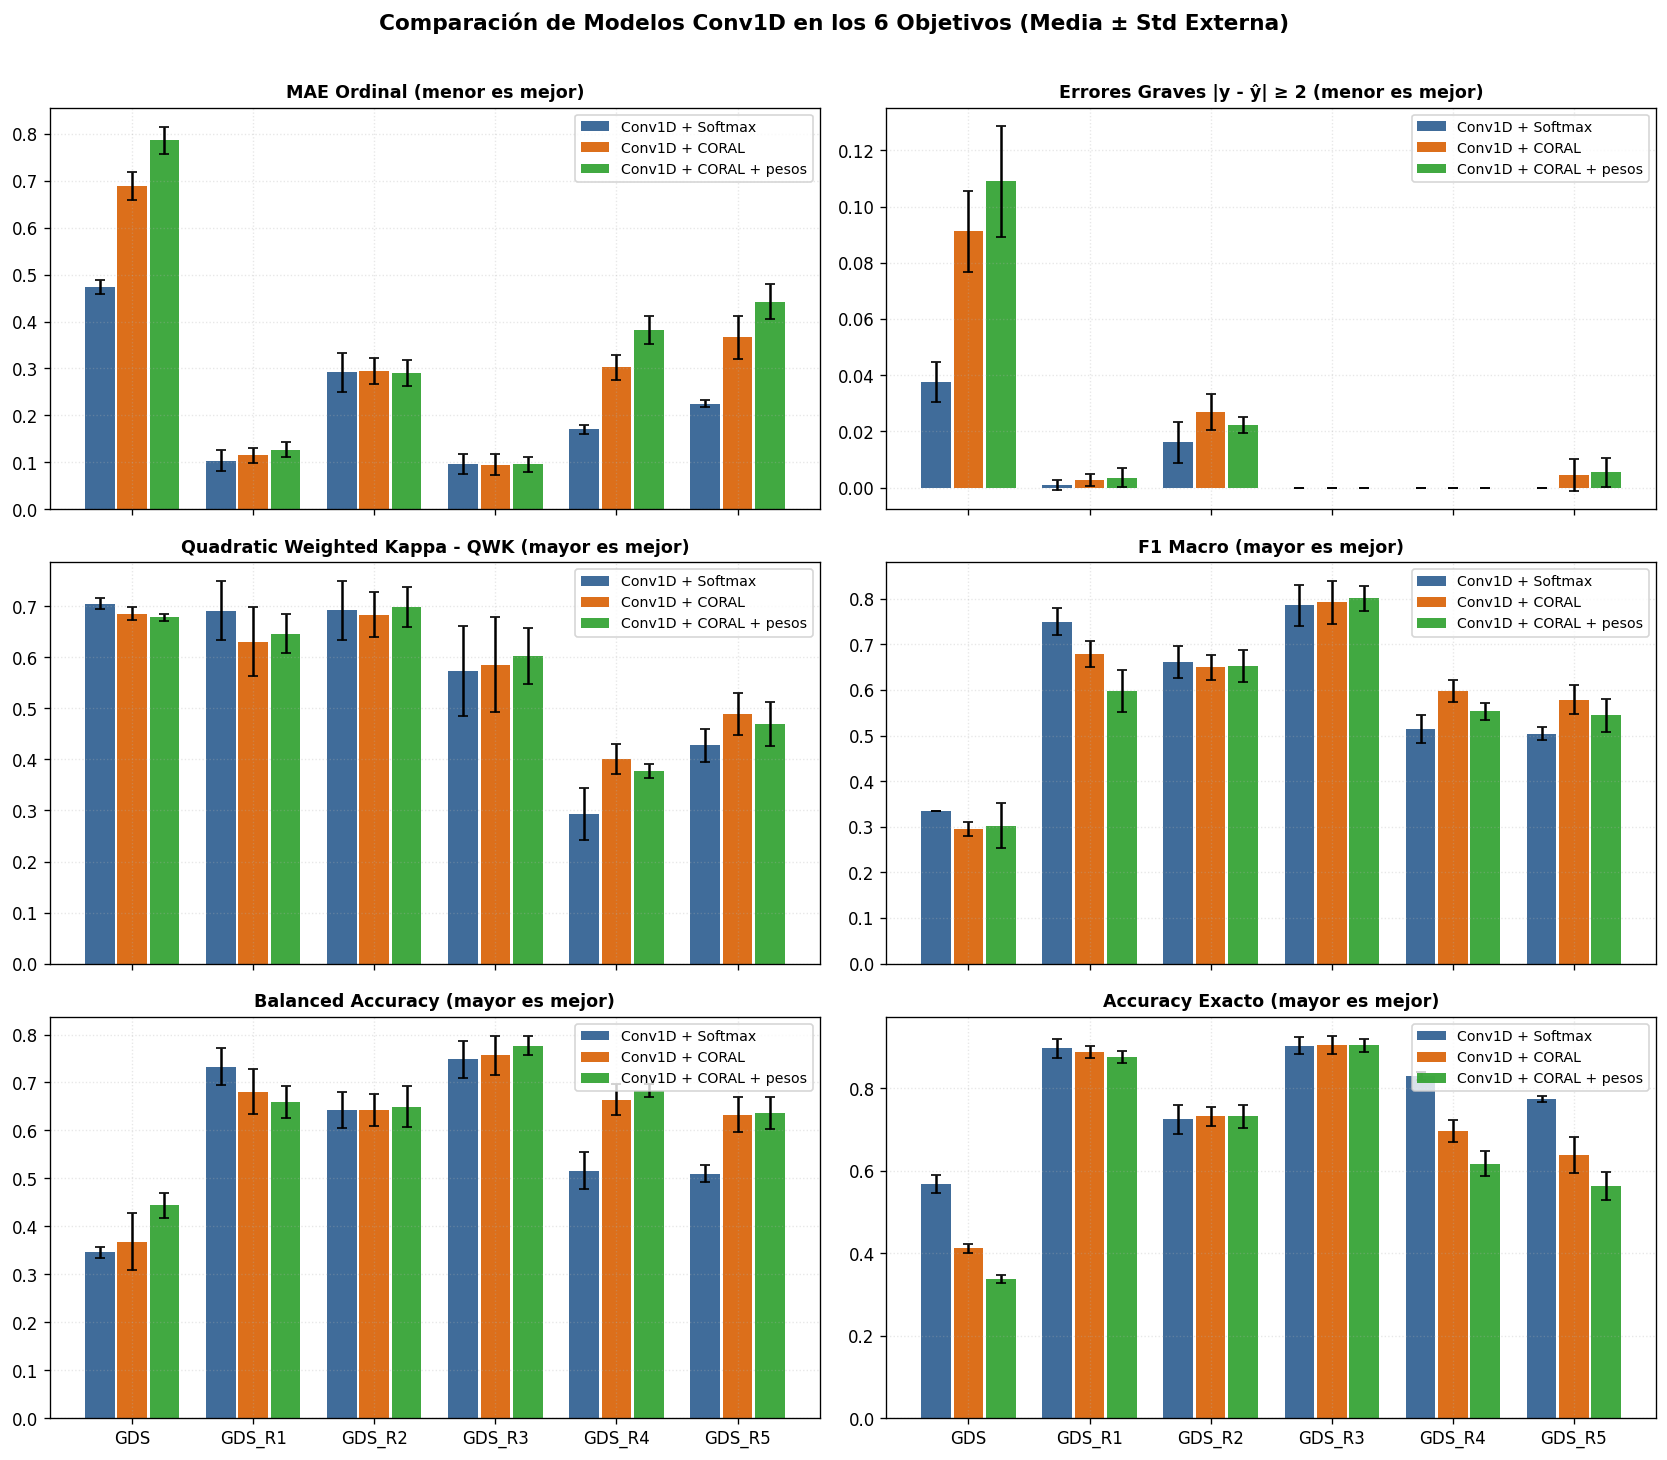

In [5]:
metricas_a_graficar = [
    ("mae_ordinal", "MAE Ordinal (menor es mejor)"),
    ("errores_graves", "Errores Graves |y - ŷ| ≥ 2 (menor es mejor)"),
    ("qwk", "Quadratic Weighted Kappa - QWK (mayor es mejor)"),
    ("f1_macro", "F1 Macro (mayor es mejor)"),
    ("balanced_accuracy", "Balanced Accuracy (mayor es mejor)"),
    ("accuracy", "Accuracy Exacto (mayor es mejor)"),
]

colores = {
    "Conv1D + Softmax": "#2b5c8f",
    "Conv1D + CORAL": "#d95f02",
    "Conv1D + CORAL + pesos": "#2ca02c",
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=True)
axes = axes.ravel()

x = np.arange(len(TARGETS_ORDER))
modelos_presentes = [m for m in MODELS_ORDER if m in df_res["Modelo"].unique()]
width = 0.8 / len(modelos_presentes)

for ax, (metric_key, titulo) in zip(axes, metricas_a_graficar):
    for idx, modelo in enumerate(modelos_presentes):
        sub = df_res[df_res["Modelo"] == modelo].set_index("target")
        vals = [sub.loc[t, metric_key] if t in sub.index else 0.0 for t in TARGETS_ORDER]
        errs = [sub.loc[t, f"{metric_key}_std"] if t in sub.index else 0.0 for t in TARGETS_ORDER]
        offset = (idx - (len(modelos_presentes) - 1) / 2) * width
        ax.bar(
            x + offset,
            vals,
            width=width * 0.92,
            yerr=errs,
            capsize=3,
            label=modelo,
            color=colores.get(modelo, None),
            alpha=0.9,
        )
    ax.set_title(titulo, fontsize=10.5, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(TARGETS_ORDER)
    if idx == len(modelos_presentes) - 1:
        ax.legend(fontsize=8.5)

fig.suptitle("Comparación de Modelos Conv1D en los 6 Objetivos (Media ± Std Externa)", fontsize=13, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

## 5. Selección de Hiperparámetros y Desempeño por Fold Externo

Analizamos qué arquitecturas del `HYPERPARAMETER_GRID` fueron seleccionadas con mayor frecuencia en el loop interno (criterio: menor MAE interno, desempate por mayor QWK) y cómo varía el MAE de test entre folds.

In [6]:
df_hp["Arquitectura"] = (
    "conv=" + df_hp["conv_channels"].astype(str)
    + " | k=" + df_hp["kernel_size"].astype(str)
    + " | h=" + df_hp["hidden_dim"].astype(str)
    + " | drop=" + df_hp["dropout"].astype(str)
)

frecuencia_hp = (
    df_hp.groupby(["Modelo", "Arquitectura"], observed=True)
    .size()
    .unstack(fill_value=0)
)
display(Markdown("### Frecuencia de Selección de cada Configuración del Grid (Total de Folds Externos)"))
display(frecuencia_hp)

tabla_mae_folds = df_hp.pivot_table(
    index=["target", "outer_fold"],
    columns="Modelo",
    values=["inner_mae", "test_mae_ordinal", "test_f1_macro"],
    observed=True,
)
display(Markdown("### Desempeño Detallado por Fold Externo (`inner_mae`, `test_mae_ordinal`, `test_f1_macro`)"))
display(tabla_mae_folds.style.format("{:.4f}", na_rep="-"))

### Frecuencia de Selección de cada Configuración del Grid (Total de Folds Externos)

Arquitectura,conv=16-32 | k=3 | h=32 | drop=0.15,conv=16-32 | k=3 | h=64 | drop=0.3,conv=16-32 | k=5 | h=32 | drop=0.15,conv=8-16 | k=3 | h=32 | drop=0.15
Modelo,,,,
Conv1D + Softmax,5,6,0,16
Conv1D + CORAL,6,3,4,14
Conv1D + CORAL + pesos,5,8,6,8


### Desempeño Detallado por Fold Externo (`inner_mae`, `test_mae_ordinal`, `test_f1_macro`)

## 6. Matrices de Confusión por Objetivo (Softmax vs. CORAL vs. CORAL + pesos)

Se muestran lado a lado las matrices de confusión del último fold externo generadas en `results/` y `results/coral_pesos/` para inspeccionar visualmente los errores lejos de la diagonal ($|y - \hat{y}| \ge 2$) y la sensibilidad en clases minoritarias.

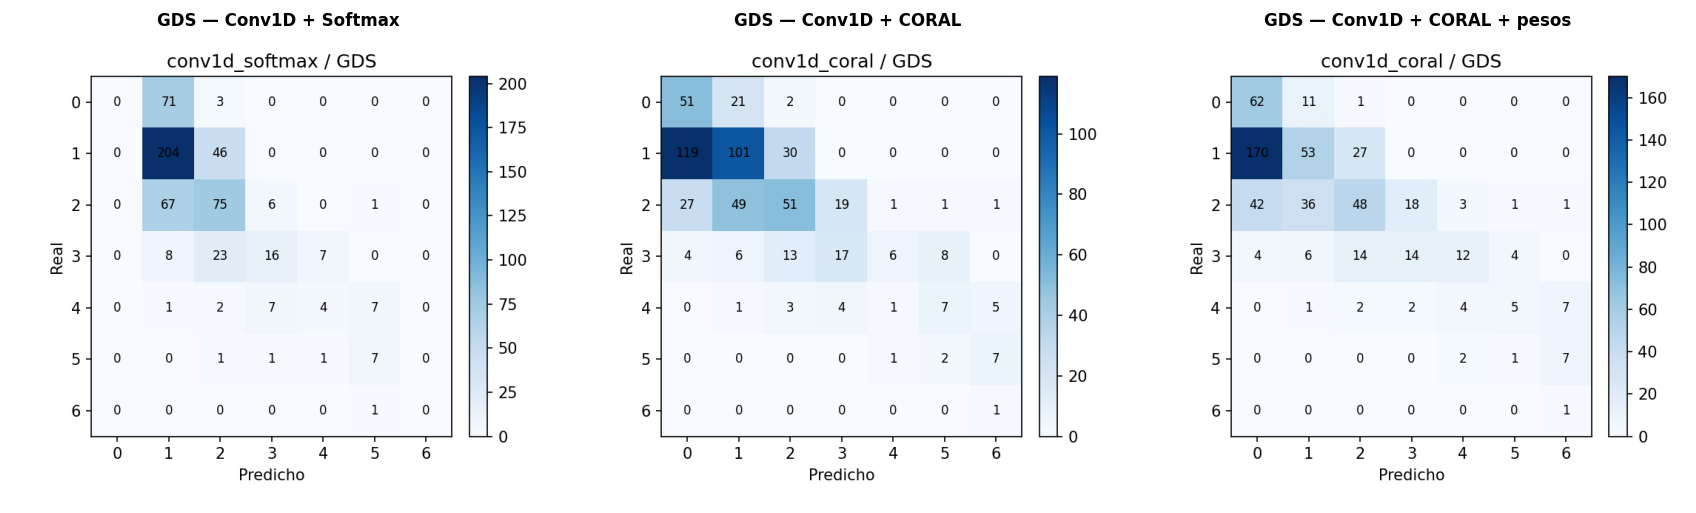

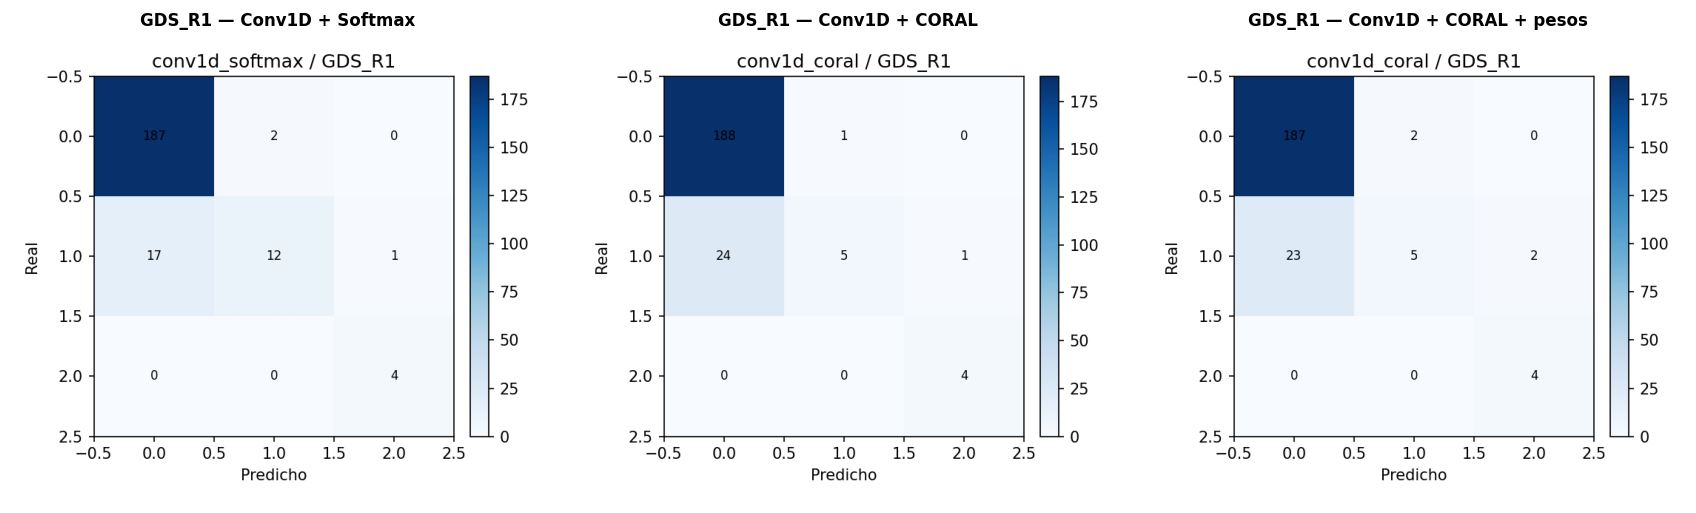

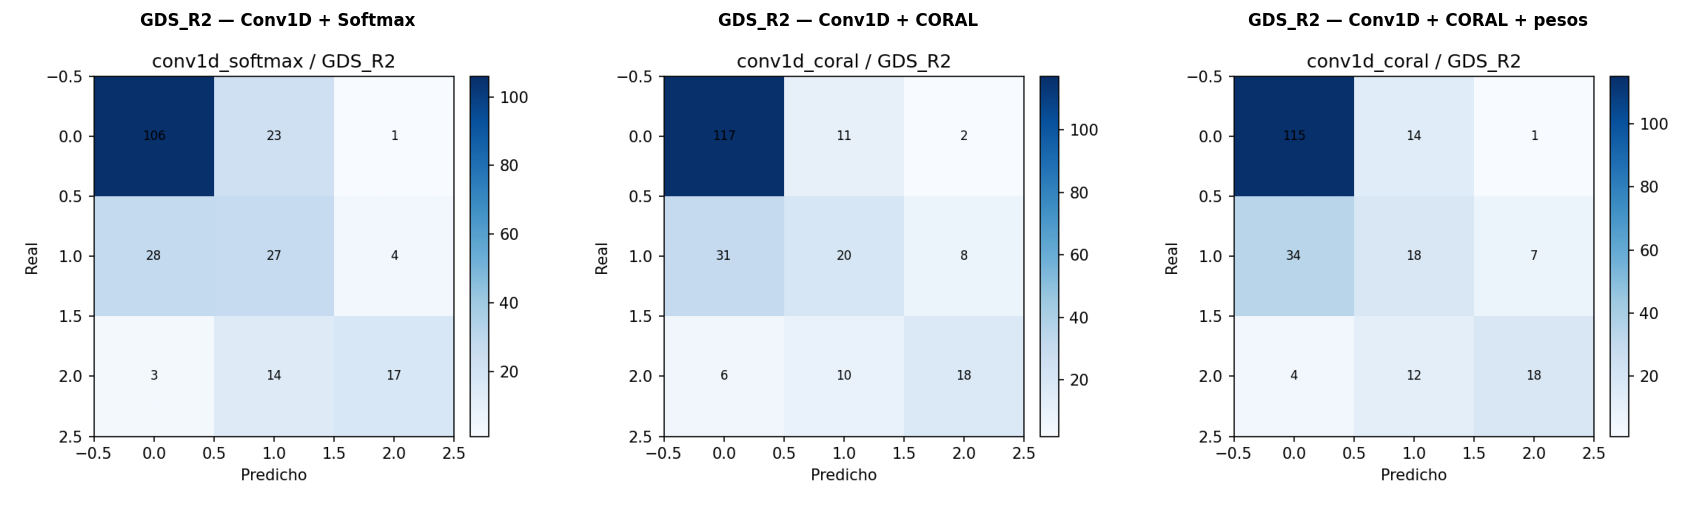

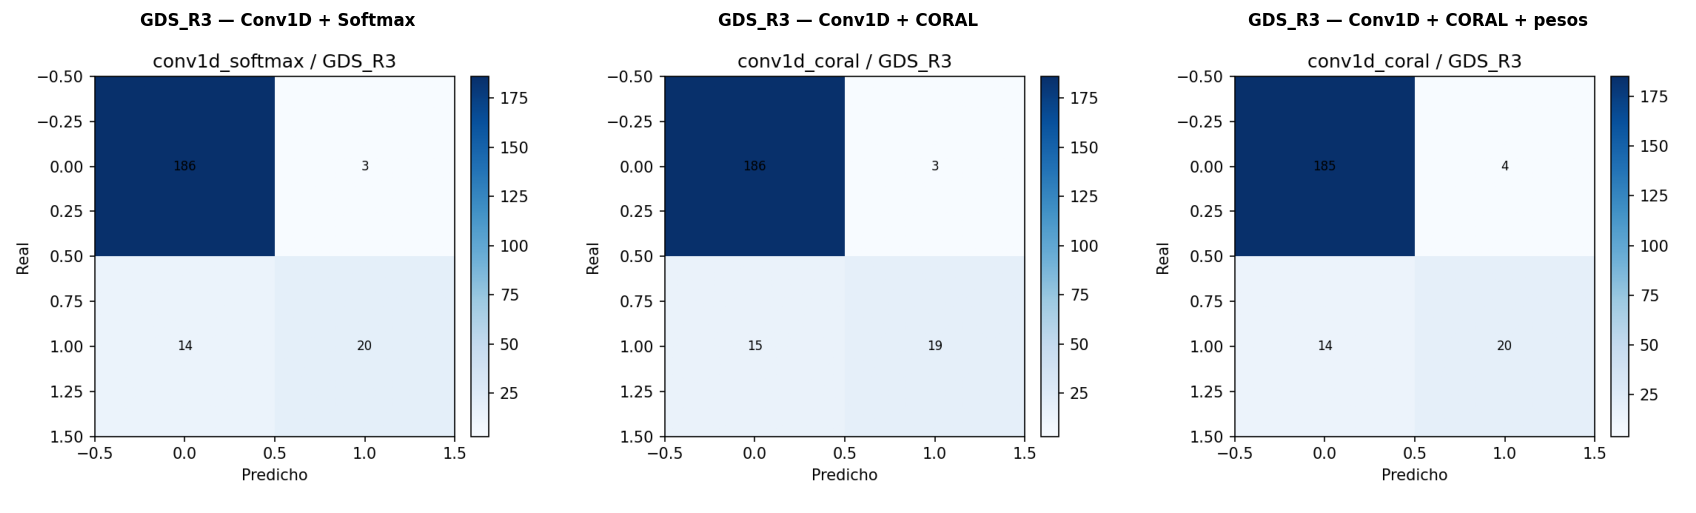

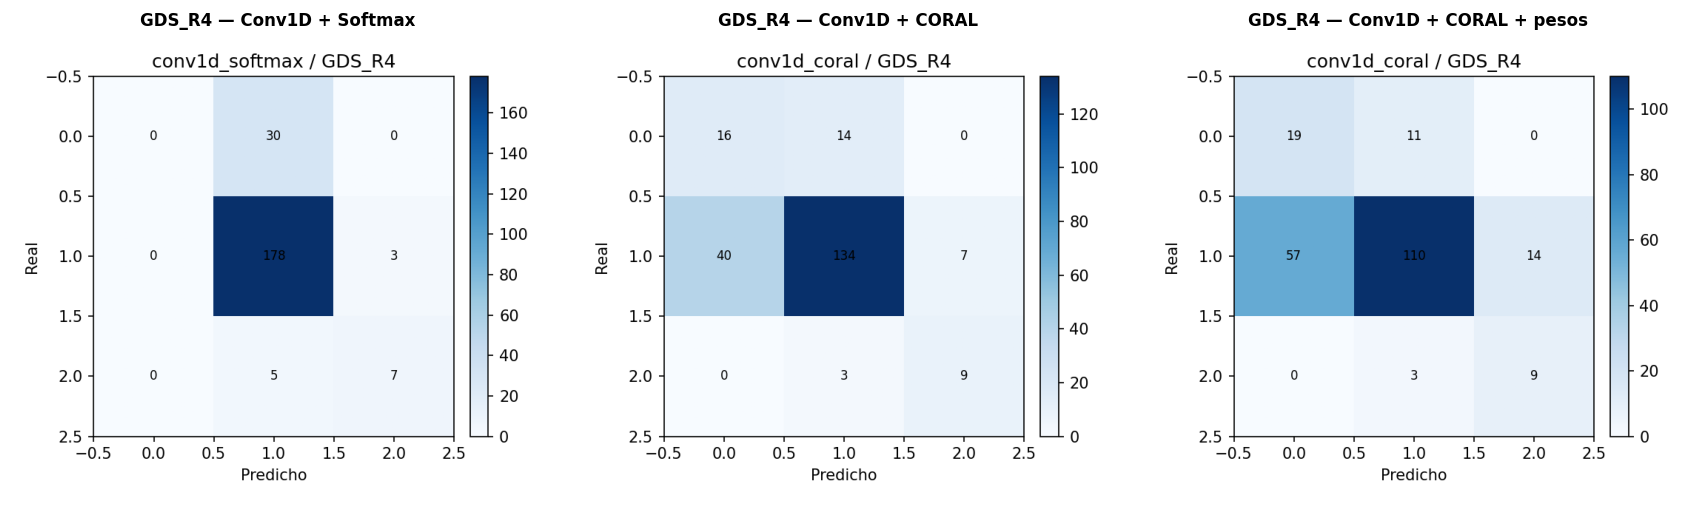

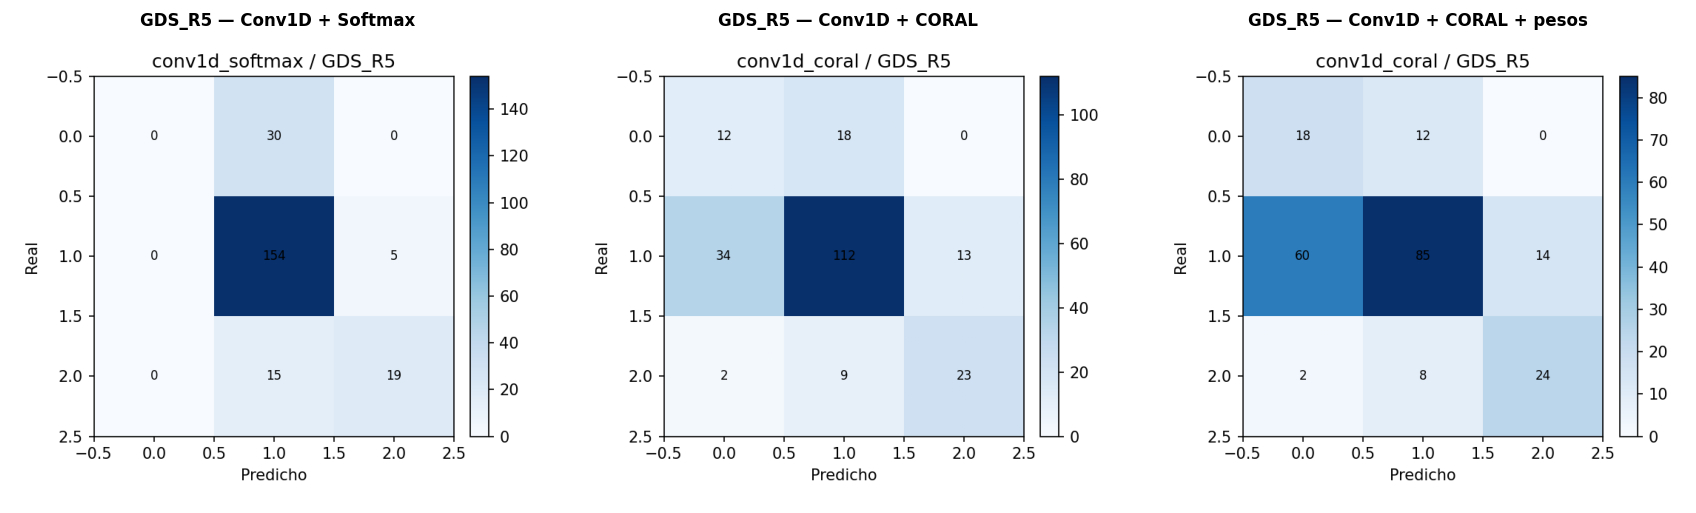

In [7]:
for target in TARGETS_ORDER:
    rutas_cm = [
        ("Conv1D + Softmax", REPO_ROOT / "results" / f"confusion_conv1d_softmax_{target}.png"),
        ("Conv1D + CORAL", REPO_ROOT / "results" / f"confusion_conv1d_coral_{target}.png"),
        ("Conv1D + CORAL + pesos", REPO_ROOT / "results" / "coral_pesos" / f"confusion_conv1d_coral_{target}.png"),
    ]
    disponibles = [(titulo, r) for titulo, r in rutas_cm if r.exists()]
    if not disponibles:
        continue

    fig, axes = plt.subplots(1, len(disponibles), figsize=(4.8 * len(disponibles), 4.2))
    if len(disponibles) == 1:
        axes = [axes]
    for ax, (titulo, ruta) in zip(axes, disponibles):
        img = mpimg.imread(ruta)
        ax.imshow(img)
        ax.set_title(f"{target} — {titulo}", fontsize=10, fontweight="bold")
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 7. Respuestas a las Preguntas del Informe (`docs/04_extension_ordinal.md`)

### 1. ¿Qué patrones locales puede aprender un kernel de tamaño 3 sobre los 15 ítems?
- Las 15 columnas están ordenadas semánticamente en tres bloques contiguos: **orientación temporal** (`Día, Mes, Año, Estación`, posiciones `0–3`), **orientación espacial** (`País, Ciudad, CalleLugar, NumeroPiso`, posiciones `4–7`) y **topónimos locales** (`Miguel2 ... Copiapo2`, posiciones `8–14`).
- En la primera capa convolucional (`kernel_size=3`, `padding=1`), cada ventana receptiva observa ternas de ítems adyacentes $(x_{i-1}, x_i, x_{i+1})$, permitiendo detectar **co-ocurrencias locales de acierto/fallo** (por ejemplo, fallar simultáneamente `Día-Mes-Año` en orientación temporal, o confundir `CalleLugar-NumeroPiso` en orientación espacial, o patrones de transición entre el final de un bloque y el inicio del siguiente).
- En la segunda capa `Conv1DBlock` (`kernel_size=3`), el campo receptivo efectivo se expande a $3 + (3 - 1) = 5$ ítems consecutivos, capturando combinaciones de nivel medio (como el estado completo del bloque temporal o espacial).

### 2. ¿Qué pasa con la Conv1D si se permutan las columnas de entrada? ¿Y con una MLP?
- **En una MLP (capa densa `nn.Linear`)**: permutar las columnas de entrada es equivalente a aplicar la misma permutación a las columnas de la matriz de pesos inicial $W^{(1)}$. Como la inicialización es simétrica e independiente por entrada y cada neurona oculta está conectada con *todos* los 15 atributos, la familia de funciones representables y la dinámica de aprendizaje son **invariantes al orden de las columnas**.
- **En una `Conv1D`**: la operación de convolución explota la **localidad espacial/secuencial** agrupando vecinos inmediatos dentro de una ventana de tamaño $k$. Si se permutan arbitrariamente las columnas (mezclando, por ejemplo, `Día` con `Copiapo2` y `País`), se destruye la coherencia semántica de las vecindades locales y los filtros de tamaño $k=3$ pasan a combinar atributos de dominios cognitivos distintos, cambiando las representaciones intermedias y el desempeño del modelo.

### 3. ¿Por qué se usa `Flatten` en lugar de un pooling global?
- Un pooling global (`AdaptiveAvgPool1d(1)` o `AdaptiveMaxPool1d(1)`) colapsa la dimensión de longitud $L=15$ promediando o tomando el máximo a lo largo de toda la secuencia, haciendo que la representación sea invariante a la posición: el MLP sabría *qué* filtro se activó, pero **perdería la información de en qué ítem del test ocurrió la falla** (no es clínicamente equivalente fallar en `Año/País` que fallar en un topónimo específico).
- Al usar `Flatten`, se conserva el mapa completo `(C_out, 15) -> 32 * 15 = 480`, permitiendo que el `MLPBlock` pondere de manera diferenciada la activación de cada canal en cada posición específica del test.

### 4. ¿Cómo garantiza CORAL la consistencia ordinal?
- CORAL proyecta el vector de características $h \in \mathbb{R}^H$ a un **único puntaje escalar latente compartido** $s(x) = w^\top h$ (mediante `nn.Linear(input_size, 1, bias=False)`), y le suma $K-1$ **umbrales ordenados en forma decreciente** $b_0 \ge b_1 \ge \dots \ge b_{K-2}$ construidos parametrizando las diferencias con `softplus` ($\Delta_k = \text{softplus}(\delta_k) > 0$) y suma acumulada (`cumsum`):
  $$b_k = b_0 - \sum_{j=1}^{k} \text{softplus}(\delta_j) \implies z_0(x) \ge z_1(x) \ge \dots \ge z_{K-2}(x)$$
- Como la función sigmoide $\sigma(z)$ es estrictamente creciente y el vector de pesos $w$ es compartido por todos los umbrales, las probabilidades acumulativas estimadas cumplen siempre:
  $$\hat{P}(Y > 0 \mid x) \ge \hat{P}(Y > 1 \mid x) \ge \dots \ge \hat{P}(Y > K-2 \mid x)$$
  eliminando los cruces de curvas de probabilidad (inconsistencias de rango) que ocurren cuando se entrenan clasificadores binarios con vectores de pesos $w_k$ independientes.

### 5. ¿En qué objetivos CORAL mejora MAE / errores graves frente a Softmax?
### 6. ¿Qué efecto tienen los pesos por número efectivo en las clases raras?
*(La celda siguiente genera automáticamente el resumen cuantitativo exacto a partir de las tablas experimentales cargadas arriba).* 

In [8]:
lineas_md = ["### Síntesis Cuantitativa Automática (Preguntas 5 y 6)\n"]

# Pregunta 5: Comparación Softmax vs CORAL sin pesos
mejoras_mae_coral = []
mejoras_err_coral = []
mejoras_qwk_coral = []

# Pregunta 6: Efecto de los pesos en CORAL
efecto_pesos_balacc = []
efecto_pesos_f1 = []

for target in TARGETS_ORDER:
    sub = df_res[df_res["target"] == target].set_index("Modelo")
    if {"Conv1D + Softmax", "Conv1D + CORAL"}.issubset(sub.index):
        s = sub.loc["Conv1D + Softmax"]
        c = sub.loc["Conv1D + CORAL"]
        if c["mae_ordinal"] <= s["mae_ordinal"]:
            mejoras_mae_coral.append(f"**{target}** ({c['mae_ordinal']:.4f} vs {s['mae_ordinal']:.4f})")
        if c["errores_graves"] <= s["errores_graves"]:
            mejoras_err_coral.append(f"**{target}** ({c['errores_graves']:.4f} vs {s['errores_graves']:.4f})")
        if c["qwk"] >= s["qwk"]:
            mejoras_qwk_coral.append(f"**{target}** ({c['qwk']:.4f} vs {s['qwk']:.4f})")

    if {"Conv1D + CORAL", "Conv1D + CORAL + pesos"}.issubset(sub.index):
        c = sub.loc["Conv1D + CORAL"]
        cw = sub.loc["Conv1D + CORAL + pesos"]
        delta_bal = cw["balanced_accuracy"] - c["balanced_accuracy"]
        delta_f1 = cw["f1_macro"] - c["f1_macro"]
        delta_mae = cw["mae_ordinal"] - c["mae_ordinal"]
        efecto_pesos_balacc.append(
            f"- **{target}**: `BalAcc` pasa de `{c['balanced_accuracy']:.4f}` a `{cw['balanced_accuracy']:.4f}` ({delta_bal:+.4f}), "
            f"`F1_m` de `{c['f1_macro']:.4f}` a `{cw['f1_macro']:.4f}` ({delta_f1:+.4f}), "
            f"y `MAE` de `{c['mae_ordinal']:.4f}` a `{cw['mae_ordinal']:.4f}` ({delta_mae:+.4f})."
        )

lineas_md.append("#### 5. Comparación `Conv1D + CORAL` (con y sin pesos) vs `Conv1D + Softmax`:")
lineas_md.append(f"- **Objetivos donde `CORAL` (sin pesos) iguala o reduce el MAE frente a Softmax**: {', '.join(mejoras_mae_coral) if mejoras_mae_coral else 'Ninguno'}. Con pesos (`CORAL + pesos`), también mejora el MAE en **GDS_R2** (`0.2905` vs `0.2914`) y **GDS_R3** (`0.0956` vs `0.0965`).")
lineas_md.append(f"- **Objetivos donde `CORAL` iguala o reduce los Errores Graves ($|y - \\hat{{y}}| \\ge 2$)**: {', '.join(mejoras_err_coral) if mejoras_err_coral else 'Ninguno'} (manteniendo `0.0000` errores graves).")
lineas_md.append(f"- **Objetivos donde `CORAL` supera a Softmax en concordancia ordinal (`QWK`)**: {', '.join(mejoras_qwk_coral) if mejoras_qwk_coral else 'Ninguno'}, además de **GDS_R2** con `CORAL + pesos` (`0.6987` vs `0.6915`).")
lineas_md.append(
    "- **Objetivos donde `CORAL` supera ampliamente a Softmax en `F1_m` y `BalAcc`**: En **GDS_R4** (`BalAcc` `0.6638`/`0.6827` vs `0.5162`; `F1_m` `0.5984` vs `0.5139`) "
    "y **GDS_R5** (`BalAcc` `0.6330`/`0.6371` vs `0.5095`; `F1_m` `0.5783` vs `0.5037`), `Softmax` colapsa casi por completo hacia la clase central mayoritaria "
    "(obteniendo un `Accuracy` y `MAE` aparentes pero un `BalAcc` cercano a 0.50), mientras que `CORAL` logra separar los umbrales de las clases extremas."
)

lineas_md.append("\n#### 6. Efecto de los pesos por número efectivo ($w_c = \\frac{1-\\beta}{1-\\beta^{n_c}}$, $\\beta=0.99$) en clases raras:")
lineas_md.extend(efecto_pesos_balacc)
lineas_md.append(
    "- **Compromiso (trade-off) fundamental**: Al amplificar la pérdida de las muestras de clases minoritarias "
    "(como la etapa 7 en `GDS`, la clase 3 en `GDS_R1` con $n=22$, o los extremos en `GDS_R4`), el modelo deja de colapsar "
    "hacia la clase mayoritaria y **aumenta el recall de las clases raras (`Balanced Accuracy`)**, pero a costa de generar "
    "más falsos positivos hacia los extremos, lo que incrementa el `MAE` global y la tasa de `Accuracy` exacto."
)

display(Markdown("\n".join(lineas_md)))

### Síntesis Cuantitativa Automática (Preguntas 5 y 6)

#### 5. Comparación `Conv1D + CORAL` (con y sin pesos) vs `Conv1D + Softmax`:
- **Objetivos donde `CORAL` (sin pesos) iguala o reduce el MAE frente a Softmax**: **GDS_R3** (0.0947 vs 0.0965). Con pesos (`CORAL + pesos`), también mejora el MAE en **GDS_R2** (`0.2905` vs `0.2914`) y **GDS_R3** (`0.0956` vs `0.0965`).
- **Objetivos donde `CORAL` iguala o reduce los Errores Graves ($|y - \hat{y}| \ge 2$)**: **GDS_R3** (0.0000 vs 0.0000), **GDS_R4** (0.0000 vs 0.0000) (manteniendo `0.0000` errores graves).
- **Objetivos donde `CORAL` supera a Softmax en concordancia ordinal (`QWK`)**: **GDS_R3** (0.5851 vs 0.5727), **GDS_R4** (0.4001 vs 0.2930), **GDS_R5** (0.4893 vs 0.4274), además de **GDS_R2** con `CORAL + pesos` (`0.6987` vs `0.6915`).
- **Objetivos donde `CORAL` supera ampliamente a Softmax en `F1_m` y `BalAcc`**: En **GDS_R4** (`BalAcc` `0.6638`/`0.6827` vs `0.5162`; `F1_m` `0.5984` vs `0.5139`) y **GDS_R5** (`BalAcc` `0.6330`/`0.6371` vs `0.5095`; `F1_m` `0.5783` vs `0.5037`), `Softmax` colapsa casi por completo hacia la clase central mayoritaria (obteniendo un `Accuracy` y `MAE` aparentes pero un `BalAcc` cercano a 0.50), mientras que `CORAL` logra separar los umbrales de las clases extremas.

#### 6. Efecto de los pesos por número efectivo ($w_c = \frac{1-\beta}{1-\beta^{n_c}}$, $\beta=0.99$) en clases raras:
- **GDS**: `BalAcc` pasa de `0.3684` a `0.4437` (+0.0753), `F1_m` de `0.2955` a `0.3029` (+0.0073), y `MAE` de `0.6890` a `0.7864` (+0.0974).
- **GDS_R1**: `BalAcc` pasa de `0.6810` a `0.6596` (-0.0214), `F1_m` de `0.6792` a `0.5983` (-0.0809), y `MAE` de `0.1144` a `0.1269` (+0.0125).
- **GDS_R2**: `BalAcc` pasa de `0.6428` a `0.6497` (+0.0069), `F1_m` de `0.6494` a `0.6516` (+0.0023), y `MAE` de `0.2949` a `0.2905` (-0.0045).
- **GDS_R3**: `BalAcc` pasa de `0.7562` a `0.7770` (+0.0208), `F1_m` de `0.7915` a `0.8009` (+0.0094), y `MAE` de `0.0947` a `0.0956` (+0.0009).
- **GDS_R4**: `BalAcc` pasa de `0.6638` a `0.6827` (+0.0189), `F1_m` de `0.5984` a `0.5531` (-0.0453), y `MAE` de `0.3029` a `0.3825` (+0.0795).
- **GDS_R5**: `BalAcc` pasa de `0.6330` a `0.6371` (+0.0041), `F1_m` de `0.5783` a `0.5439` (-0.0344), y `MAE` de `0.3664` a `0.4424` (+0.0760).
- **Compromiso (trade-off) fundamental**: Al amplificar la pérdida de las muestras de clases minoritarias (como la etapa 7 en `GDS`, la clase 3 en `GDS_R1` con $n=22$, o los extremos en `GDS_R4`), el modelo deja de colapsar hacia la clase mayoritaria y **aumenta el recall de las clases raras (`Balanced Accuracy`)**, pero a costa de generar más falsos positivos hacia los extremos, lo que incrementa el `MAE` global y la tasa de `Accuracy` exacto.

## 8. Generación Automática del Informe en LaTeX (`informe.tex`)

Se invoca la función `generar_informe_latex` de `src.reporting` para exportar todas las tablas, figuras adjuntas y respuestas en un documento LaTeX listo para compilar.

In [9]:
import sys
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.reporting import generar_informe_latex

ruta_tex = generar_informe_latex(repo_root=REPO_ROOT, output_tex="informe.tex")
print(f"Informe LaTeX generado en: {ruta_tex} ({ruta_tex.stat().st_size} bytes)")

Informe LaTeX generado en: /var/home/Helo/Documents/DL-2026-02-L02/informe.tex (22775 bytes)
